In [ ]:
import pandas as pd, numpy as np
p = pd.read_csv("painel.csv")
p["mes"] = pd.to_datetime(p["mes"])
import matplotlib.pyplot as plt



feats = ["lag1","lag2","lag3","lag6","lag12","roll3","roll12","m","ano","logpop"]
tr = p[p.mes < "2025-01-01"]
te = p[p.mes >= "2025-01-01"]

print(p.shape, p.y.sum())
print(p.mes.min(), p.mes.max())
print(p[feats + ["y"]].isna().sum().sum(), "valores nulos")
print(len(tr), "treino |", len(te), "teste")

(16830, 14) 19428
2013-01-01 00:00:00 2026-09-01 00:00:00
0 valores nulos
14688 treino | 2142 teste


In [ ]:

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

from sklearn.preprocessing import RobustScaler

f = p.groupby("cidade").agg(media=("y","mean"), pop=("pop","first"))
f["taxa"] = f.media * 12 / f["pop"] * 1e5

def tendencia(d):
    t = d.ano + (d.m - 1) / 12
    return np.polyfit(t, d.y, 1)[0]

f["tend"] = p.groupby("cidade").apply(tendencia)
f["tend_rel"] = f["tend"] / f["media"]

feats = pd.DataFrame({
    "log_pop":  np.log1p(f["pop"]),
    "log_taxa": np.log1p(f["taxa"]),
    "tend_rel": f["tend_rel"],
}, index=f.index)

X = RobustScaler().fit_transform(feats)

for k in range(2, 8):
    km = KMeans(k, n_init=10, random_state=42).fit(X)
    print(k, round(silhouette_score(X, km.labels_), 3), np.bincount(km.labels_))


K = 4
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X)
f["cluster"] = km.labels_
print(np.bincount(f["cluster"]))

/tmp/ipykernel_1245/2724611891.py:14: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  f["tend"] = p.groupby("cidade").apply(tendencia)


2 0.258 [50 52]
3 0.262 [39 21 42]
4 0.264 [33 18 28 23]
5 0.249 [16 18 35 16 17]
6 0.265 [23 18 26 18 14  3]
7 0.277 [17 22  4 15 24 18  2]
[33 18 28 23]


In [ ]:
Lolf = p.groupby("cidade").agg(media=("y","mean"), pop=("pop","first"))


f["taxa"] = f.media * 12 / f["pop"] * 1e5


def tendencia(d):
    t = d.ano + (d.m - 1) / 12
    return np.polyfit(t, d.y, 1)[0]

f["tend"] = p.groupby("cidade").apply(tendencia)

print(f.describe().round(2))
print(f.sort_values("taxa", ascending=False).head(10))

        media        pop    taxa    tend  tend_rel  cluster
count  102.00     102.00  102.00  102.00    102.00   102.00
mean     1.15   30663.56   42.11   -0.08     -0.07     1.40
std      3.88   96462.87   16.63    0.26      0.05     1.16
min      0.04    2731.00    8.25   -2.52     -0.17     0.00
25%      0.26    9054.00   30.07   -0.08     -0.11     0.00
50%      0.54   15417.00   41.90   -0.03     -0.07     1.50
75%      0.90   24052.00   52.15   -0.01     -0.03     2.00
max     38.56  957916.00   99.79    0.05      0.12     3.00
                        media    pop       taxa      tend  tend_rel  cluster
cidade                                                                      
BARRA DE SAO MIGUEL  0.660606   7944  99.789435 -0.012631 -0.019120        3
COQUEIRO SECO        0.375758   5581  80.793602 -0.018112 -0.048202        2
FLEXEIRAS            0.642424   9618  80.152744 -0.066904 -0.104142        2
ROTEIRO              0.424242   6474  78.636223 -0.040681 -0.095890        

/tmp/ipykernel_1245/3243846943.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  f["tend"] = p.groupby("cidade").apply(tendencia)


In [ ]:

km3 = KMeans(4, n_init=10, random_state=42).fit(X)
print(np.bincount(km3.labels_))


from sklearn.metrics import silhouette_samples
s = silhouette_samples(X, km.labels_)
print([round(s[km.labels_ == c].mean(), 3) for c in range(K)])

[33 18 28 23]
[np.float64(0.239), np.float64(0.262), np.float64(0.272), np.float64(0.29)]


In [ ]:
km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X)
f["cluster"] = km.labels_

resumo = f.groupby("cluster").agg(
    n=("media", "size"),
    pop_mediana=("pop", "median"),
    taxa_mediana=("taxa", "median"),
    taxa_media=("taxa", "mean"),
    tend_rel_mediana=("tend_rel", "median"),
    tend_mediana=("tend", "median"),

)

resumo["media_mensal"] = f.groupby("cluster")["media"].mean()
resumo["vitimas_mensal"] = resumo["media_mensal"] * 12

tot = (p.merge(f[["cluster"]], left_on="cidade", right_index=True)
         .groupby("cluster")["y"].sum())
resumo["vitimas_total"] = tot
resumo["pop_total"] = f.groupby("cluster")["pop"].sum()

print(resumo.round(2))

for c_, d in f.groupby("cluster"):
    print(f"\n--- Cluster {c_} (n={len(d)}) ---")
    print("Top por taxa:", list(d.sort_values("taxa", ascending=False).index[:13]))
    print("Top por população:", list(d.sort_values("pop", ascending=False).index[:5]))

          n  pop_mediana  taxa_mediana  taxa_media  tend_rel_mediana  \
cluster                                                                
0        33      31786.0         48.30       44.36             -0.09   
1        18       8091.5         19.32       20.14             -0.02   
2        28       8909.5         46.99       48.28             -0.10   
3        23      15559.0         44.86       48.55             -0.02   

         tend_mediana  media_mensal  vitimas_mensal  vitimas_total  pop_total  
cluster                                                                        
0               -0.10          2.74           32.85          14904    2336129  
1               -0.00          0.16            1.86            461     169548  
2               -0.03          0.38            4.56           1754     267034  
3               -0.01          0.61            7.30           2309     354972  

--- Cluster 0 (n=33) ---
Top por taxa: ['MURICI', 'PILAR', 'RIO LARGO', 'SAO SEBASTIAO

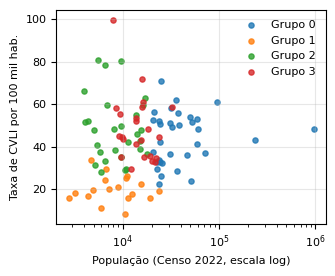

In [ ]:


plt.rcParams.update({
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

cores = plt.cm.tab10.colors


fig, ax = plt.subplots(figsize=(3.4, 2.8))
for c_, d in f.groupby("cluster"):
    ax.scatter(d["pop"], d["taxa"], s=14, alpha=.8,
               color=cores[c_], label=f"Grupo {c_}")
ax.set_xscale("log")
ax.set_xlabel("População (Censo 2022, escala log)")
ax.set_ylabel("Taxa de CVLI por 100 mil hab.")
ax.legend(loc="upper right", frameon=False)
ax.grid(alpha=.3)
fig.tight_layout()
fig.savefig("rq4_dispersao.png", dpi=300)
plt.show()


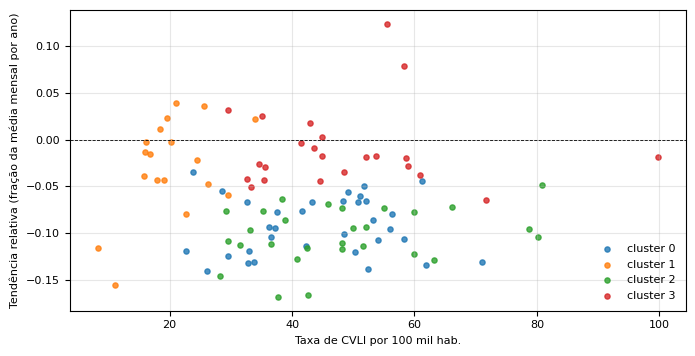

In [ ]:


plt.rcParams.update({
    "font.size": 8,
    "axes.labelsize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

cores = plt.cm.tab10.colors


fig, ax = plt.subplots(figsize=(7, 3.6))
for c_, d in f.groupby("cluster"):
    ax.scatter(d["taxa"], d["tend_rel"], s=14, alpha=.8,
               color=cores[c_], label=f"cluster {c_}")
ax.axhline(0, color="k", lw=.6, ls="--")
ax.set_xlabel("Taxa de CVLI por 100 mil hab.")
ax.set_ylabel("Tendência relativa (fração da média mensal por ano)")
ax.legend(loc="lower right", frameon=False)
ax.grid(alpha=.3)
fig.tight_layout()
fig.savefig("rq4_tendencia.png", dpi=300)
plt.show()

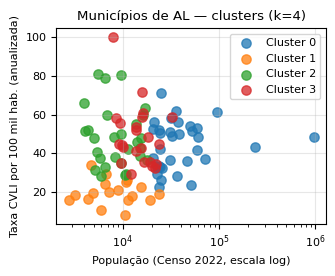

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(3.4, 2.8))
for c_, d in f.groupby("cluster"):
    plt.scatter(d["pop"], d["taxa"], label=f"Cluster {c_}", alpha=0.75, s=45)
plt.xscale("log")
plt.xlabel("População (Censo 2022, escala log)")
plt.ylabel("Taxa CVLI por 100 mil hab. (anualizada)")
plt.title(f"Municípios de AL — clusters (k={K})")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("rq4_dispersao.png", dpi=150)
plt.show()

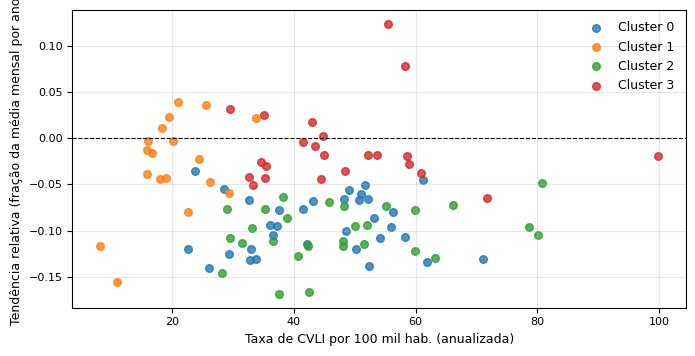

In [ ]:
plt.figure(figsize=(7, 3.6))
for c_, d in f.groupby("cluster"):
    plt.scatter(d["taxa"], d["tend_rel"], label=f"Cluster {c_}",
                color=cores[c_], alpha=0.8, s=30)
plt.axhline(0, color="black", lw=0.8, ls="--")
plt.xlabel("Taxa de CVLI por 100 mil hab. (anualizada)", fontsize=9)
plt.ylabel("Tendência relativa (fração da média mensal por ano)", fontsize=9)
plt.legend(fontsize=9, frameon=False)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("rq4_tendencia.png", dpi=150)
plt.show()